In [ ]:
import glob
import numpy as np
import pandas as pd
import xarray as xr
import xesmf as xe

def anomaly_calculation(model, clim):
    ano_list = []
    for i in range(1,13):
        ano_list.append(model.sel(time=model.time[model.time.dt.month.isin(i)]) - clim.sel(month=i))
    return xr.concat(ano_list, dim='time').sortby('time')

# def regrid(in_grid,out_grid, var): 
#     reg_bil = xe.Regridder(in_grid,out_grid, "bilinear")
#     var_bil = reg_bil(in_grid[var])
#     return var_bil

def clim(ds):
    return ds.groupby('time.month').mean('time')


def global_mean(data, lat='lat', lon='lon'):
    weights_lat_model = np.cos(np.deg2rad(data.lat))
    try:
        mean = data.weighted(weights_lat_model).mean([lat, lon])
    except ValueError:
        mean = data.weighted(weights_lat_model).mean([lat])
    return mean


def shift_lon(ds, lon_name = 'longitude'):
    # Adjust lon values to make sure they are within (-180, 180)
    ds['_longitude_adjusted'] = xr.where(
        ds[lon_name] > 180,
        ds[lon_name] - 360,
        ds[lon_name])

    # reassign the new coords to as the main lon coords
    # and sort DataArray using new coordinate values
    ds = (
        ds
        .swap_dims({lon_name: '_longitude_adjusted'})
        .sel(**{'_longitude_adjusted': sorted(ds._longitude_adjusted)})
        .drop_vars(lon_name))

    ds = ds.rename({'_longitude_adjusted': lon_name})
    return ds

def calculate_nino34_index(ds):
    # ds needs to be tos-anomalies
    # 170° - 120°W -> 190 - 240°E
    nino = ds.sel(longitude=slice(190,240), latitude=slice(5,-5)).mean(['longitude', 'latitude'])
    #nino_gm = global_mean(nino).compute()
    nino_gm = nino.compute()
    return nino_gm

def calculate_nao(ds):
    ds_south = ds.sel(latitude=slice(55,20), longitude=slice(-90,60))
    # ds_south = global_mean(ds_south)
    ds_south = ds_south.mean(['latitude', 'longitude'])
    ds_north = ds.sel(latitude=slice(90,55), longitude=slice(-90,60))
    # ds_north = global_mean(ds_north)
    ds_north = ds_north.mean(['latitude', 'longitude'])
    nao = (ds_south - ds_north).compute()
    nao = nao.to_dataset(name='zg')
    return nao


def calculate_djf_mean(ds):
    ds_seasons = ds.resample(time='QE-FEB').mean()
    ds_djf = ds_seasons.sel(time=(ds_seasons['time.season'] == 'DJF'))
    return ds_djf


def calculate_tercile_flags(data, var):
    # calculate terciles to cluster indices into 3 categories: -1 (negative/cold), 0 (netural), 1 (positive/warm state)
    df = data[var].to_dataframe()
    df = df.reset_index()
    df = df.set_index('time')
    tertiles = df[var].quantile([1/3, 2/3]).to_list()
    tertiles = [-float('inf')] + tertiles + [float('inf')]

    df['tercile'] = pd.cut(df[var], bins=tertiles, labels=[-1,0,1])
    return df['tercile']

def calculate_index(data, var):
    # calculate index and tercile flags for a given variable and path (ENSO: var='tos', NAO: var='zg')
    index = (data - data.mean('time'))/ np.sqrt(data.var('time'))
    index['tercile'] = calculate_tercile_flags(index, var)
    return index


In [ ]:
path = '/sto4/data/Intermediate/VolMIP/reanalysis/'
ds_zg = xr.open_mfdataset(glob.glob(path + 'ERA5_zg_monthly.nc'))
ds_tos = xr.open_mfdataset(glob.glob(path + 'ERA5_sst_monthly.nc'))
ds_zg = ds_zg.rename({'valid_time': 'time'}).squeeze()
ds_tos = ds_tos.rename({'valid_time': 'time'})

ds_prep = shift_lon(ds_zg.sel(latitude=slice(100,0)))
# calculate nao index
nao = calculate_nao(ds_prep.z)
nao_djf = calculate_djf_mean(nao)
nao_idx = calculate_index(nao_djf, 'zg').rename({'zg': 'nao', 'tercile': 'nao_flag'}).to_pandas().drop(['number', 'pressure_level'], axis=1)

# calculate nino index
nino = calculate_nino34_index(ds_tos)
nino = nino#.to_dataset(name='sst')
nino_djf = calculate_djf_mean(nino)
enso = calculate_index(nino_djf, 'sst').rename({'sst': 'enso', 'tercile': 'enso_flag'}).to_pandas().drop(['number'], axis=1)

enso[['nao', 'nao_flag']] = nao_idx[['nao', 'nao_flag']]
flags = enso

In [3]:
ta = xr.open_mfdataset('/sto4/data/Intermediate/VolMIP/reanalysis/ERA5_zonal_common-grid_monthly_core_1940-2023.nc')[['t']]

In [4]:
ta = calculate_djf_mean(ta).sel(time=slice('1940', '2023'))

In [5]:
flags = flags.loc['1940':'2023']

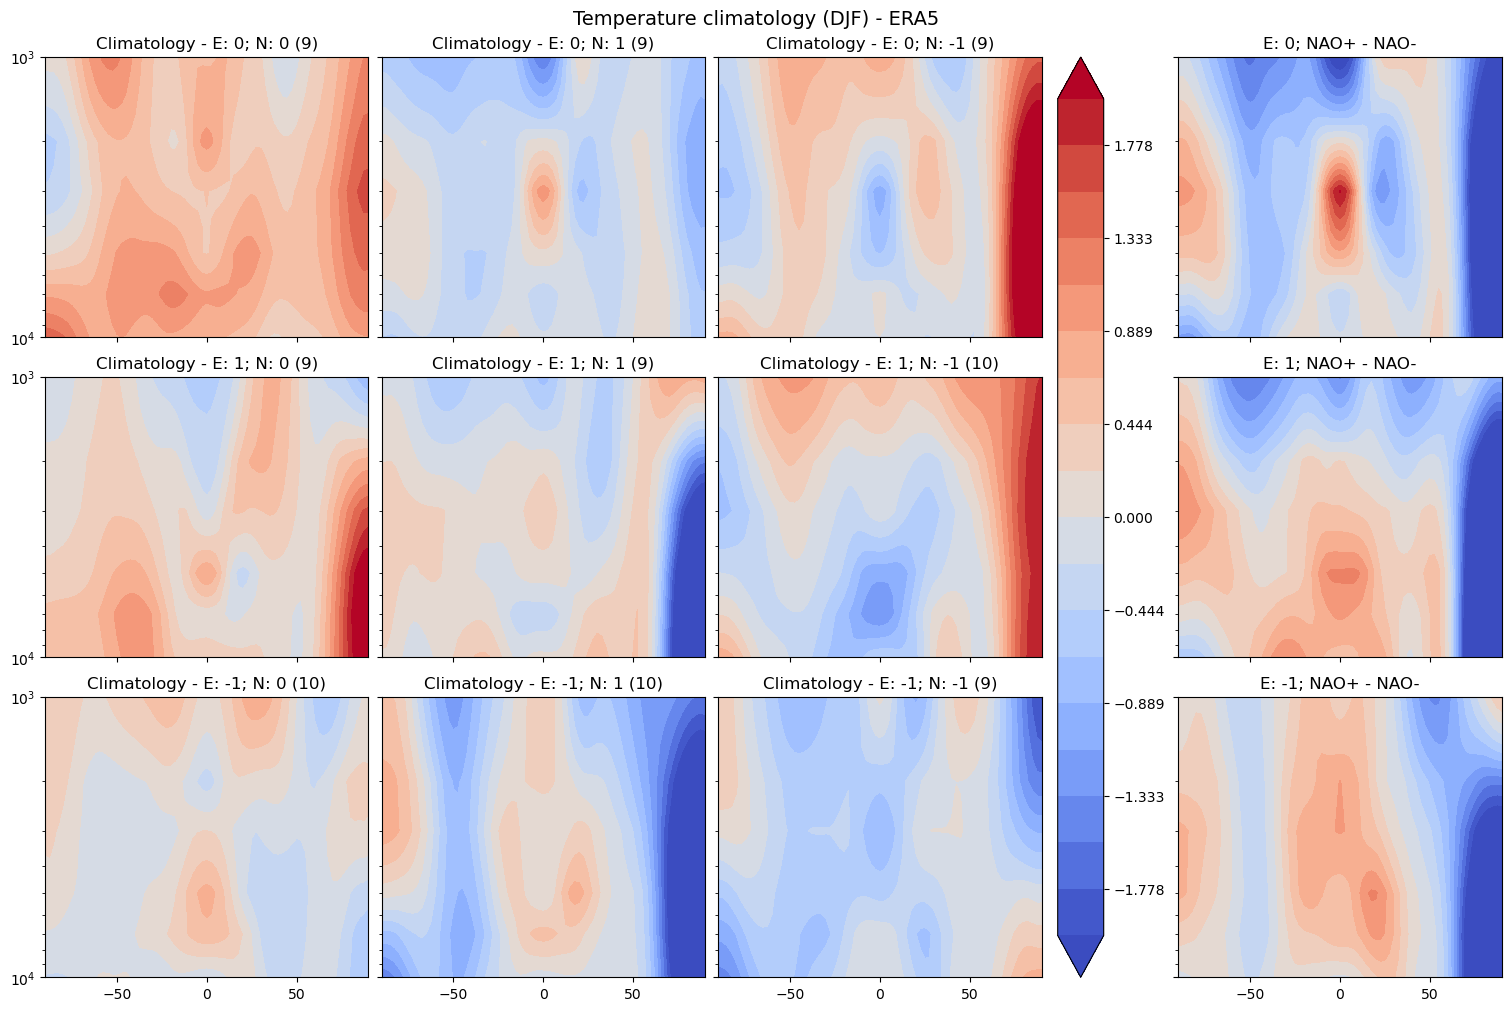

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(3,4, figsize=(15,10), sharex=True, sharey=True, layout='constrained')

plotdir='/home/kperny/VolMIP_stratosphere/plots/'
mean = ta.t.mean('time').squeeze()

for i, enso in enumerate([0,1,-1]):
    for j, nao in enumerate([0,1,-1]):
        years = flags.where((flags.nao_flag == nao) & (flags.enso_flag == enso)).dropna().index
        tmp = ta.t.sel(time=years).mean('time').squeeze()
        d = axs[i, j].contourf(tmp.lat, tmp.pre, (tmp - mean).T, levels=np.linspace(-2,2,19), cmap='coolwarm', extend='both')
        axs[i, j].set_title('Climatology - E: ' + str(enso) + '; N: ' + str(nao) + ' (' + str(len(years)) + ')')
    years = flags.where((flags.nao_flag == 1) & (flags.enso_flag == enso)).dropna().index
    naop = ta.t.sel(time=years).mean('time').squeeze()
    axs[i, j+1].contourf(tmp.lat, tmp.pre, (naop - tmp).T, levels=np.linspace(-2,2,19), cmap='coolwarm', extend='both')
    axs[i, j+1].set_title('E: ' + str(enso) + '; NAO+ - NAO-')
axs[0,0].set_ylim(10000,1000)
axs[0,0].set_yscale('log')
fig.suptitle('Temperature climatology (DJF) - ERA5', fontsize=14)
fig.colorbar(d, ax=axs[0:3, 2])

plt.savefig(plotdir + 'background/ta_difference_ERA5.png', dpi=200)
